In [1]:
import tomllib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plt_config  # noqa: F401
import seaborn as sns

# Introduction

This file examines the accuracy and time complexity of the extended Kalman filter and the particle filter with various number of particles.

In [2]:
try:
    time_arr_03 = np.load("../scripts/saved_variables/module3/time_arr_03_temp.npy")
    error_arr_03 = np.load("../scripts/saved_variables/module3/error_arr_03_temp.npy")
    G_ests = np.load("../scripts/saved_variables/module3/G_ests_03_temp.npy")
    G_trues = np.load("../scripts/saved_variables/module3/G_trues_03_temp.npy")
    # all_vars = np.load("../scripts/saved_variables/module3/vars_03_temp.npy")
    states = np.load("../scripts/saved_variables/module3/states_03_temp.npy")
    print("Loaded variables")
except FileNotFoundError:
    print("Run 03_Estimator_Comparison.py")

Loaded variables


In [3]:
with open("../config.toml", "rb") as f:
    cfg = tomllib.load(f)
curr_module = "03"
num_particles = cfg[curr_module]["num_particles"]
low_perc = cfg[curr_module]["low_perc"]
high_perc = cfg[curr_module]["high_perc"]
CI = cfg[curr_module]["CI"]
converge_time = cfg[curr_module]["converge_time"]
deviations = cfg[curr_module]["deviations"]
dev_perc = cfg[curr_module]["dev_perc"]
plot_particles_idx = cfg[curr_module]["plot_particles_idx"]
num_deviations = len(deviations)
num_patients = cfg[curr_module]["num_patients"]

# Plot Results

<Axes: xlabel='Estimator', ylabel='Time to run (s)'>

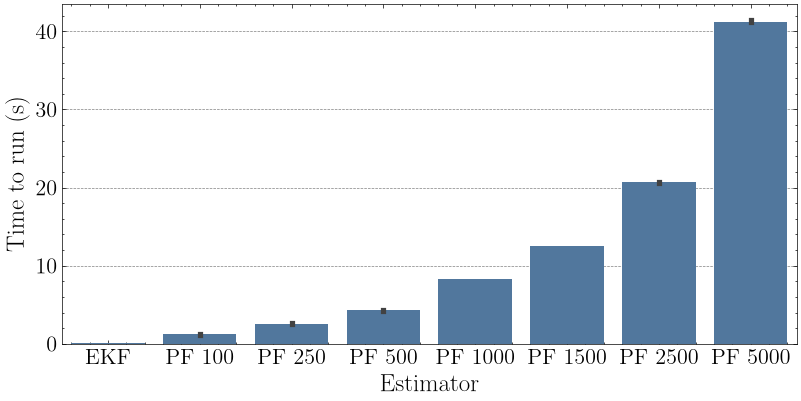

In [4]:
mean_time_run = np.average(time_arr_03.T, axis=0)
filters = ["EKF"]
pfs = [f"PF {particles}" for particles in num_particles]
filters.extend(pfs)
df = pd.DataFrame(time_arr_03.T, columns=filters).melt(
    var_name="Estimator", value_name="Time to run (s)"
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(df, x="Estimator", y="Time to run (s)", ax=ax)

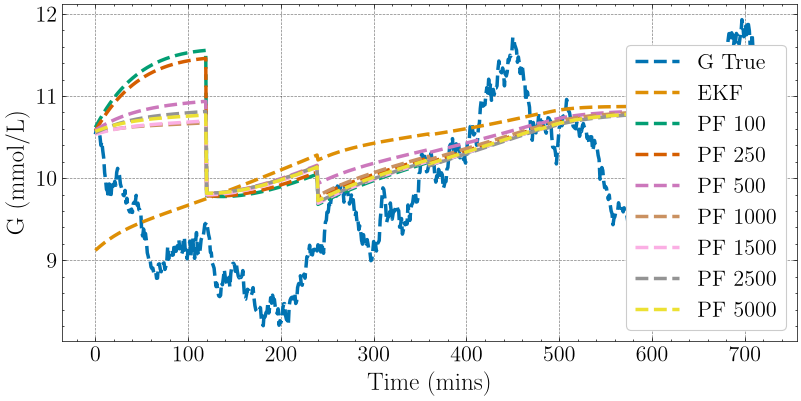

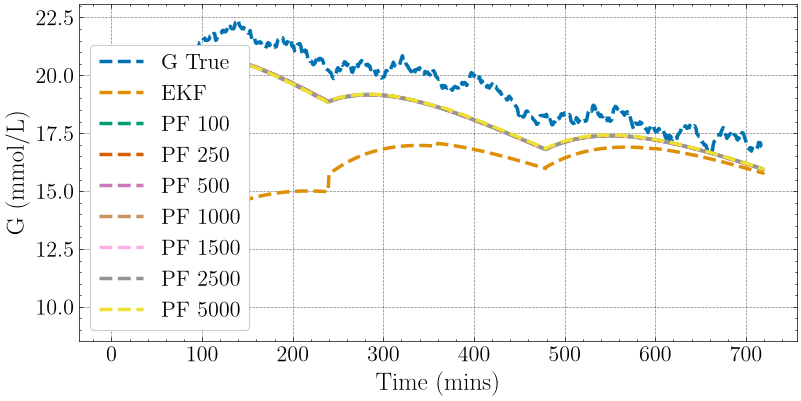

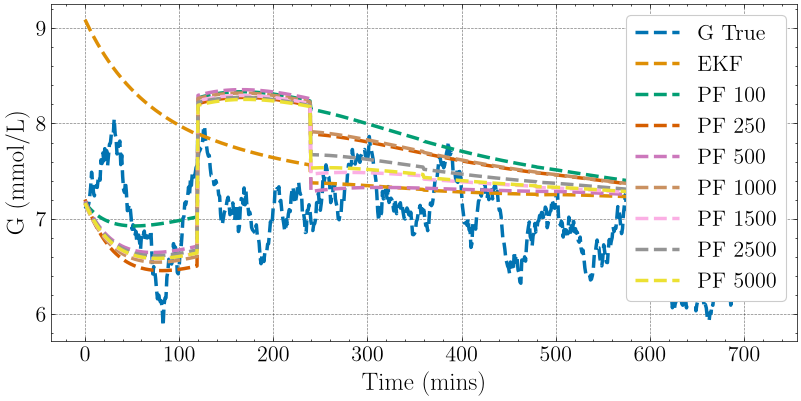

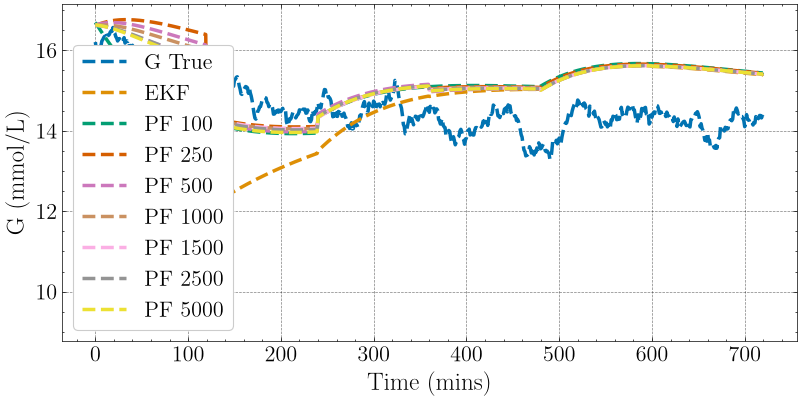

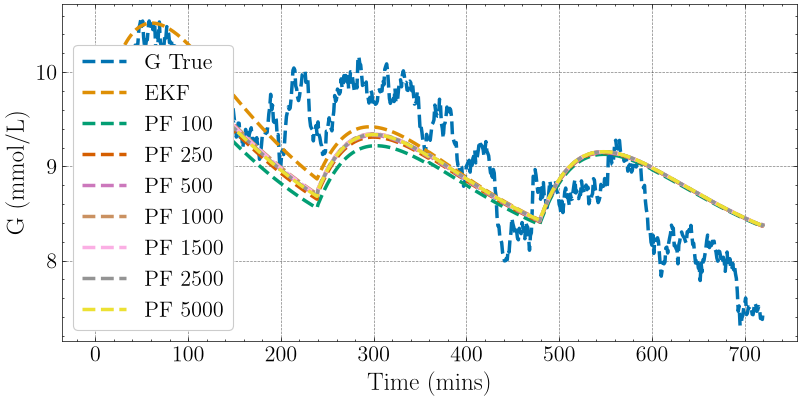

In [5]:
time = np.arange(G_ests.shape[2])
num_filters = len(filters)
palette = sns.color_palette("colorblind", num_filters + 1)
for i in range(5):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(time, G_trues[i, :], color=palette[0], label="G True", linestyle="--")
    for j in range(num_filters):
        # G_est = states[deviation, plot_idx, i, :, 2]
        G_est = G_ests[j, i, :]
        # G_std = np.sqrt(all_vars[deviation, plot_idx, i, :, 0, 0])
        ax.plot(time, G_est, linestyle="--", color=palette[j + 1], label=filters[j])

    ax.legend()
    ax.set_xlabel("Time (mins)")
    ax.set_ylabel("G (mmol/L)")

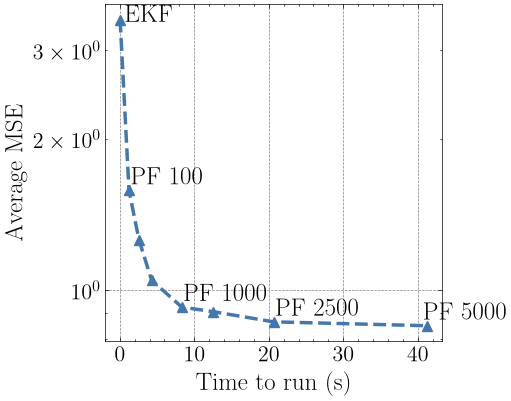

In [6]:
total_avg_time = np.average(time_arr_03, axis=1)
complexity = total_avg_time
total_avg_err = np.average(error_arr_03, axis=(1, 2))
total_std_err = np.std(error_arr_03, axis=(1, 2))

fig, ax = plt.subplots(figsize=(5.1, 4))
ax.semilogy(complexity, total_avg_err, linestyle="--", marker="^")
ax.set_xlabel(r"Time to run (s)")
ax.set_ylabel("Average MSE")
for x, y, label in zip(complexity, total_avg_err, filters):
    if label in {"EKF", "PF 100", "PF 1000", "PF 2500", "PF 5000"}:
        if label == "EKF":
            ax.annotate(
                label,
                xy=(x, y),
                xytext=(3, -5),
                textcoords="offset points",
                ha="left",
                va="bottom",
            )
        elif label == "PF 5000":
            ax.annotate(
                label,
                xy=(x, y),
                xytext=(-3, 1),
                textcoords="offset points",
                ha="left",
                va="bottom",
            )
        else:
            ax.annotate(
                label,
                xy=(x, y),
                xytext=(1, 1),
                textcoords="offset points",
                ha="left",
                va="bottom",
            )
fig.savefig("figures/5_6.pdf", format="pdf")

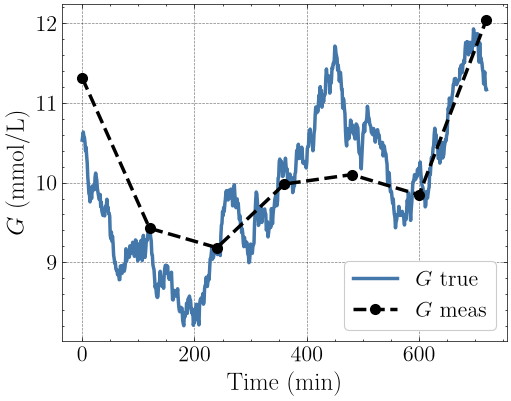

In [7]:
fig, ax = plt.subplots(figsize=(5.1, 4))
sample = 0
time = np.arange(len(G_trues[sample, :]))
time_meas = np.arange(0, len(G_trues[sample, :]), 120)
ax.plot(time, G_trues[sample, :], label=r"$G$ true")
ax.plot(
    time_meas,
    G_trues[sample, ::120]
    + np.random.randn(len(G_trues[sample, ::120])) * np.sqrt(0.25),
    linestyle="--",
    marker="o",
    color="black",
    label=r"$G$ meas",
)
ax.set_xlabel("Time (min)")
ax.set_ylabel(r"$G$ (mmol/L)")
ax.legend()
fig.savefig("figures/example.pdf", format="pdf")

In [8]:
print("Total average time: \n", complexity)
print("Total average MSE: \n", total_avg_err)
print(total_std_err)

Total average time: 
 [3.71442451e-02 1.23564991e+00 2.57611438e+00 4.27314698e+00
 8.31798691e+00 1.24933050e+01 2.06527461e+01 4.12446574e+01]
Total average MSE: 
 [3.45396398 1.5795659  1.25951405 1.04681924 0.92588563 0.90693925
 0.86541312 0.8501466 ]
[9.64329394 5.28329465 4.26025407 3.24972957 2.55642561 2.48419375
 2.33105015 2.25664177]
